In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/clean/selected_features.csv", sep=",")

display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,target
0,2nd phase - general contingent,Animation and Multimedia Design,2,0,1,1,0,0,0,0.000000,20,127.3,Dropout
1,International student (bachelor),Tourism,2,0,0,1,0,6,6,13.666667,19,142.5,Graduate
2,1st phase - general contingent,Communication Design,2,0,0,1,0,6,0,0.000000,19,124.8,Dropout
3,2nd phase - general contingent,Journalism and Communication,2,0,1,0,0,6,5,12.400000,20,119.6,Graduate
4,Over 23 years old,Social Service (evening attendance),2,0,1,0,0,6,6,13.000000,45,141.5,Graduate



The shape is: (3630, 13)

The columns are: Index(['application_mode_group', 'course_name', 'prev_qual_level', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'age_at_enrollment', 'admission_grade', 'target'],
      dtype='str')


In [2]:
#Check for enrolled students
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [3]:
#Save enrolled students for risk prediction
df_enrolled = df[df["target"] == "Enrolled"].copy()

#Exclude enrolled students from training
df = df[df["target"] != "Enrolled"].copy()

In [4]:
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [6]:
#SPLIT THE DATA FRAME (PLACEHOLDER)
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y
)

In [7]:
nominal_features = ['application_mode_group', 'course_name']

ordinal_features = ["prev_qual_level"]

binary_features = ["debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder"]

numerical_features = [
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_grade"
]

In [8]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaling", MinMaxScaler()),
])
nominal_pipeline = Pipeline([("encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
numerical_pipeline = Pipeline([("scaling", MinMaxScaler())])

In [9]:
# Preprocessor for column transformation
preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipeline, ordinal_features),
    ("nominal", nominal_pipeline, nominal_features),
    ("numerical", numerical_pipeline, numerical_features),
    ("binary", "passthrough", binary_features),
])

In [10]:
# Run KNN model and fit to data 
full_pipeline = Pipeline([("preprocess", preprocessor),
                         ("model", KNeighborsClassifier(n_neighbors=5))])
full_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['application_mode_group','course_name','prev_qual_level',..., 'curricular_units_2nd_sem_grade','age_at_enrollment','admission_grade']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

In [11]:
# Check Training vs Test Accuracy
print("Training accuracy:", round(full_pipeline.score(X_train, y_train), 3))
print("Test accuracy:", round(full_pipeline.score(X_test, y_test), 3))

Training accuracy: 0.869
Test accuracy: 0.799


In [12]:
y_pred_train_knn = full_pipeline.predict(X_train)
y_pred_test_knn  = full_pipeline.predict(X_test)

comparison_students = pd.DataFrame({
    "actual_student_status": y_test,
    "predicted_student_status": pd.Series(y_pred_test_knn, index=y_test.index),
})

display(comparison_students.head(10))

,actual_student_status,predicted_student_status
3060,Dropout,Dropout
13,Graduate,Graduate
1808,Graduate,Graduate
3228,Graduate,Graduate
1694,Graduate,Graduate
1664,Dropout,Dropout
595,Graduate,Dropout
1199,Graduate,Dropout
2772,Graduate,Graduate
2098,Graduate,Graduate


In [13]:
classification_metrics = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_train, y_pred_train_knn),
        "Precision (macro)": precision_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (macro)": recall_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (Dropout)": recall_score(y_train, y_pred_train_knn, pos_label="Dropout"),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test, y_pred_test_knn),
        "Precision (macro)": precision_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (macro)": recall_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (Dropout)": recall_score(y_test, y_pred_test_knn, pos_label="Dropout"),
    },
})
display(classification_metrics.round(3))

,Training,Test
Accuracy,0.869,0.799
Precision (macro),0.876,0.796
Recall (macro),0.848,0.775
Recall (Dropout),0.752,0.665


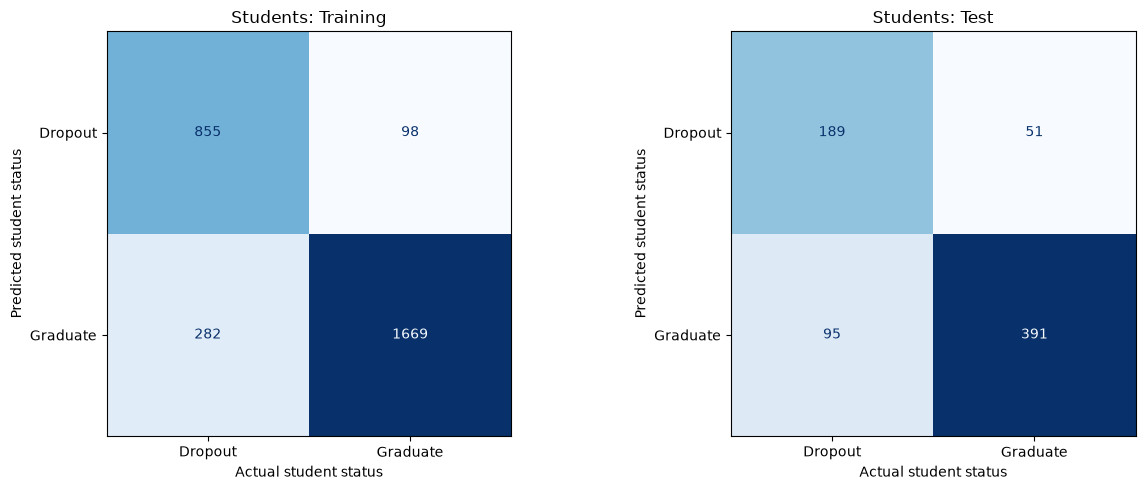

In [14]:
# One class order, used by both the matrix and the labels
class_order = ["Dropout", "Graduate"]

# Compute confusion matrices for both datasets
cm_train = confusion_matrix(y_train, y_pred_train_knn, labels=class_order)
cm_test  = confusion_matrix(y_test,  y_pred_test_knn,  labels=class_order)

# Plot the confusion matrices: train vs test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, split_name in zip(axes, [cm_train, cm_test], ["Training", "Test"]):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=class_order,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual student status")
    ax.set_ylabel("Predicted student status")
    ax.set_title(f"Students: {split_name}")

plt.tight_layout()
plt.show()